# Assignment 1
## Ákos Kappel

### Techniques

**Filtering**
- mean
- median
- gaussian
- bilateral

**Edge detection**
- sobel
- laplacian
- canny

**Thresholding**
- otsu
- adaptive

**Sharpening**


In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


class GaussianTracker:
    def __init__(self, image, ksize=0, sigmaX=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.sigmaX = sigmaX
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.GaussianBlur(self.img, (self.ksize, self.ksize), self.sigmaX)
        cv.imshow(self.window, blur)


class MedianTracker:
    def __init__(self, image, ksize=0, window='image', trackbar='ksize'):
        self.img = image
        self.ksize = ksize
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        blur = cv.medianBlur(self.img, self.ksize)
        cv.imshow(self.window, blur)


class BilateralTracker:
    def __init__(self, image, d=0, sigmaColor=0, sigmaSpace=0, window='image', trackbar='d'):
        self.img = image
        self.d = d
        self.sigmaColor = sigmaColor
        self.sigmaSpace = sigmaSpace
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.d, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.d = cv.getTrackbarPos(self.trackbar, self.window)
        blur = cv.bilateralFilter(self.img, self.d, self.sigmaColor, self.sigmaSpace)
        cv.imshow(self.window, blur)


class GlobalThresholdTracker:
    def __init__(self, image, original=None, thresh=0, maxval=255, type=cv.THRESH_BINARY, use_mask=True, window='image',
                 trackbar='threshold'):
        self.img = image
        self.original = original
        self.thresh = thresh
        self.maxval = maxval
        self.type = type
        self.use_mask = use_mask
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.thresh, self.maxval, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.thresh = cv.getTrackbarPos(self.trackbar, self.window)
        ret, thresh = cv.threshold(self.img, self.thresh, self.maxval, self.type)
        if self.use_mask:
            mask = cv.bitwise_not(thresh)
            img = self.img if self.original is None else self.original
            thresh = cv.bitwise_and(img, img, mask=mask)
        cv.imshow(self.window, thresh)


class AdaptiveThresholdTracker:
    def __init__(self, image, ksize=11, type=cv.ADAPTIVE_THRESH_GAUSSIAN_C, window='image', trackbar='threshold'):
        self.img = image
        self.ksize = ksize
        self.type = type
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.ksize, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.ksize = cv.getTrackbarPos(self.trackbar, self.window)
        if self.ksize % 2 == 0:
            self.ksize += 1
        if self.ksize < 3:
            self.ksize = 3
        adaptive = cv.adaptiveThreshold(self.img, 255, self.type, cv.THRESH_BINARY, self.ksize, 2)
        cv.imshow(self.window, adaptive)


class CannyTracker:
    def __init__(self, image, threshold1=0, threshold2=0, window='image', trackbar1='threshold1',
                 trackbar2='threshold2'):
        self.img = image
        self.threshold1 = threshold1
        self.threshold2 = threshold2
        self.window = window
        self.trackbar1 = trackbar1
        self.trackbar2 = trackbar2
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar1, self.window, self.threshold1, 255, self.update)
        cv.createTrackbar(self.trackbar2, self.window, self.threshold2, 255, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.threshold1 = cv.getTrackbarPos(self.trackbar1, self.window)
        self.threshold2 = cv.getTrackbarPos(self.trackbar2, self.window)
        if self.threshold1 > self.threshold2:
            self.threshold1, self.threshold2 = self.threshold2, self.threshold1
        canny = cv.Canny(self.img, self.threshold1, self.threshold2)
        cv.imshow(self.window, canny)


class ContourSizeTracker:
    def __init__(self, image, min_area=0, max_area=10_000, mode=cv.RETR_TREE, window='image', trackbar='area'):
        self.img = image
        self.min_area = min_area
        self.max_area = max_area
        self.mode = mode
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.min_area, self.max_area, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.min_area = cv.getTrackbarPos(self.trackbar, self.window)
        contours, hierarchy = cv.findContours(self.img, self.mode, cv.CHAIN_APPROX_SIMPLE)
        contours = [c for c in contours if self.min_area < cv.contourArea(c) < self.max_area]
        img_copy = img.copy()
        img_copy = cv.drawContours(img_copy, contours, -1, (255, 0, 0), 2)
        cv.imshow(self.window, img_copy)


class WatershedTracker:
    def __init__(self, image, dist=0, window='image', trackbar='threshold'):
        self.img = image
        self.dist = dist
        self.window = window
        self.trackbar = trackbar
        cv.namedWindow(self.window)
        cv.createTrackbar(self.trackbar, self.window, self.dist, 100, self.update)
        self.update(self.window)
        cv.waitKey(0)
        cv.destroyAllWindows()

    def update(self, x):
        self.dist = cv.getTrackbarPos(self.trackbar, self.window) / 100

        # red channel
        r = self.img[:, :, 2]

        # Otsu's thresholding
        ret, otsu = cv.threshold(r, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

        # morphological operations
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
        opening = cv.morphologyEx(otsu, cv.MORPH_OPEN, kernel, iterations=2)

        # find sure background area
        sure_bg = cv.dilate(opening, kernel, iterations=5)

        # distance transform
        dist = cv.distanceTransform(opening, cv.DIST_L2, 5)
        cv.normalize(dist, dist, 0, 1.0, cv.NORM_MINMAX)

        # find sure foreground area
        ret, sure_fg = cv.threshold(dist, self.dist * dist.max(), 255, 0)

        # find unknown region
        sure_fg = np.uint8(sure_fg)
        unknown = cv.subtract(sure_bg, sure_fg)

        # marker labelling
        ret, markers = cv.connectedComponents(sure_fg)

        markers = markers + 1
        markers[unknown == 255] = 0

        # watershed
        markers = cv.watershed(self.img, markers)
        ws = self.img.copy()
        ws[markers == -1] = [255, 0, 0]
        markers = markers.astype(np.uint8)

        cv.imshow(self.window, ws)
        cv.imshow(self.window + ' markers', markers)

In [3]:
file1 = 'images/TCGA-18-5592-01Z-00-DX1.tif'
file2 = 'images/pena.tif'
file3 = 'images/img (5).png'

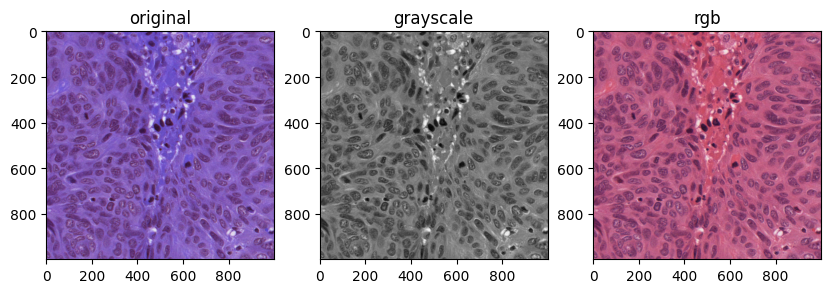

In [4]:
# load image
img = cv.imread(file1)

org_img = img.copy()

# convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# convert to rgb
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# show images
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('original')
plt.imshow(img)
plt.subplot(1, 3, 2)
plt.title('grayscale')
plt.imshow(gray, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('rgb')
plt.imshow(rgb_img)
plt.show()

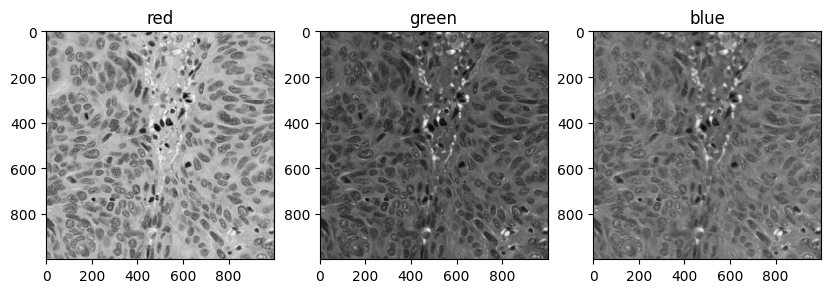

In [5]:
b, g, r = cv.split(img)

# show rgb channels in one image
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('red')
plt.imshow(r, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('green')
plt.imshow(g, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('blue')
plt.imshow(b, cmap='gray')
plt.show()

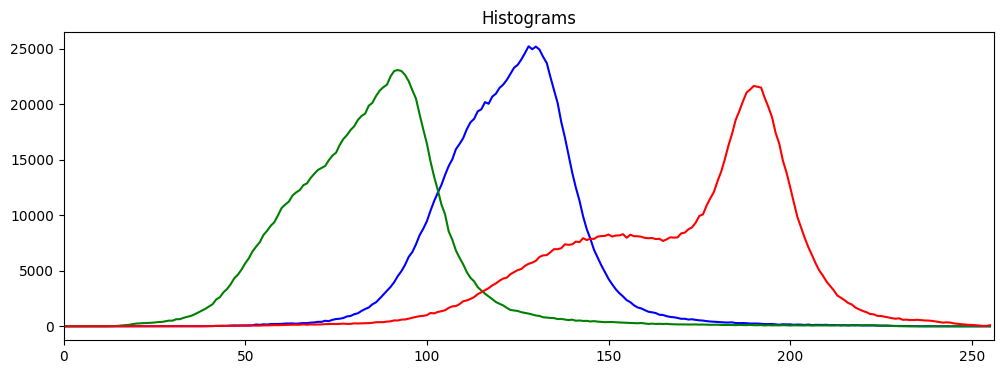

In [6]:
# create histograms
hist_b = cv.calcHist([b], [0], None, [256], [0, 256])
hist_g = cv.calcHist([g], [0], None, [256], [0, 256])
hist_r = cv.calcHist([r], [0], None, [256], [0, 256])

# plot histograms in one figure
plt.figure(figsize=(12, 4))
plt.title('Histograms')
plt.plot(hist_b, color='b')
plt.plot(hist_g, color='g')
plt.plot(hist_r, color='r')
plt.xlim([0, 256])
plt.show()

In [7]:
rg = cv.subtract(r, g)

# threshold
ret, rg_thresh = cv.threshold(rg, 75, 255, cv.THRESH_BINARY_INV)

# opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(rg_thresh, cv.MORPH_OPEN, kernel, iterations=2)

# closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(opening, cv.MORPH_CLOSE, kernel, iterations=2)

# apply mask
masked = cv.bitwise_and(img, img, mask=closing)

# show images
show_images([
    ('Original', img),
    ('Red - Green', rg),
    ('Red - Green Threshold', rg_thresh),
    ('Opening', opening),
    ('Closing', closing),
    ('Masked', masked),
])

In [8]:
GlobalThresholdTracker(gray, window='gray')
GlobalThresholdTracker(r, window='red', thresh=160)
GlobalThresholdTracker(g, window='green', thresh=60)
GlobalThresholdTracker(b, window='blue', thresh=100)

In [120]:
# blur
blur = cv.medianBlur(img, 5)
b, g, r = cv.split(blur)

# threshold red channel
ret, r_thresh = cv.threshold(r, 180, 255, cv.THRESH_BINARY)

# subtract red channel from original image
sub = cv.subtract(r, r_thresh)

# opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(sub, cv.MORPH_OPEN, kernel, iterations=2)

# closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(opening, cv.MORPH_CLOSE, kernel, iterations=1)

show_images([
    ('image', img),
    ('r_thresh', r_thresh),
    ('sub', sub),
    ('opening', opening),
    ('closing', closing),
])
# GlobalThresholdTracker(r, window='red', original=img, thresh=160)

In [86]:
tmp = r

# Otsu's thresholding
ret, otsu = cv.threshold(r, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# morphological operations
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(otsu, cv.MORPH_OPEN, kernel, iterations=2)

# find sure background area
sure_bg = cv.dilate(opening, kernel, iterations=5)

# distance transform
dist = cv.distanceTransform(opening, cv.DIST_L2, 5)
cv.normalize(dist, dist, 0, 1.0, cv.NORM_MINMAX)

# find sure foreground area
ret, sure_fg = cv.threshold(dist, 0.2 * dist.max(), 255, 0)

# find unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg, sure_fg)

# marker labelling
ret, markers = cv.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

# watershed
markers = cv.watershed(img, markers)
ws = img.copy()
ws[markers == -1] = [255, 0, 0]
markers = markers.astype(np.uint8)

show_images([
    ('otsu', otsu),
    ('opening', opening),
    ('sure_bg', sure_bg),
    ('dist', dist),
    ('sure_fg', sure_fg),
    ('unknown', unknown),
    ('markers', markers),
    ('ws', ws),
])

In [74]:
WatershedTracker(img, window='image')

In [9]:
# closing
ret, thresh = cv.threshold(r, 160, 255, cv.THRESH_BINARY_INV)
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=3)
closing = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel, iterations=3)
cv.imshow('thresh', thresh)
cv.imshow('closing', closing)
cv.imshow('opening', opening)
cv.waitKey(0)
cv.destroyAllWindows()

number of contours: 503
[18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0] [3262.0, 3325.5, 3370.5, 3440.5, 4007.0, 4085.0, 4307.0, 4392.0, 4940.0, 6478.5]


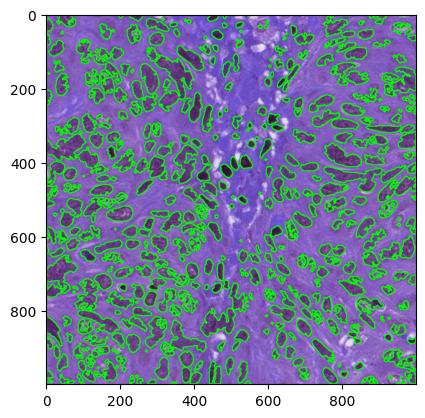

In [11]:
# contours
contours, _ = cv.findContours(opening, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 10]
print(f'number of contours: {len(contours)}')
sizes = list(sorted([cv.contourArea(c) for c in contours]))
print(sizes[:10], sizes[-10:])

img_copy = cv.drawContours(img.copy(), contours, -1, (0, 255, 0), 2)
plt.imshow(img_copy, cmap='gray')

show_images([
    ('original image', org_img),
    ('contours image', img_copy),
    ('thresh image', thresh),
    ('opening', opening),
    ('closing', closing),
])

In [13]:
# gaussian blur
blur = cv.GaussianBlur(img, (5, 5), 0)
# blur = cv.medianBlur(img, 5)

# canny edge detection
edges = cv.Canny(blur, 100, 200)

show_images([
    ('original', img),
    ('blur', blur),
    ('edges', edges),
])

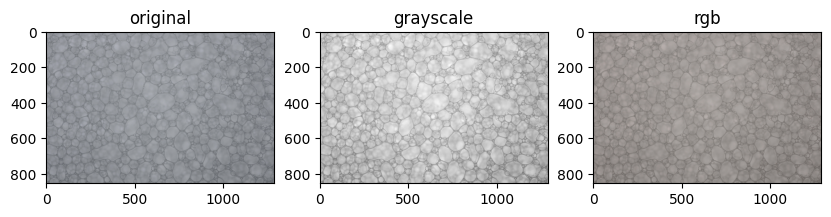

In [6]:
# load image
img = cv.imread(file2)

# resize image
img = cv.resize(img, (0, 0), fx=0.3, fy=0.3)
org_img = img.copy()

# convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# convert to rgb
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# show images
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('original')
plt.imshow(img)
plt.subplot(1, 3, 2)
plt.title('grayscale')
plt.imshow(gray, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('rgb')
plt.imshow(rgb_img)
plt.show()

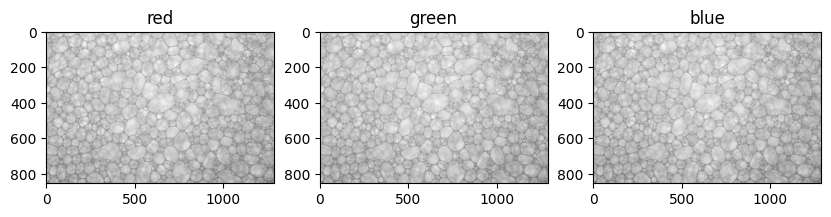

In [7]:
b, g, r = cv.split(img)

# show rgb channels in one image
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('red')
plt.imshow(r, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('green')
plt.imshow(g, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('blue')
plt.imshow(b, cmap='gray')
plt.show()

In [18]:
# invert eroded image
tmp = cv.bitwise_not(eroded)

# Otsu's thresholding
ret, otsu = cv.threshold(tmp, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# morphological operations
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(otsu, cv.MORPH_OPEN, kernel, iterations=2)

# find sure background area
sure_bg = cv.dilate(opening, kernel, iterations=10)

# distance transform
dist = cv.distanceTransform(opening, cv.DIST_L2, 5)
cv.normalize(dist, dist, 0, 1.0, cv.NORM_MINMAX)

# find sure foreground area
ret, sure_fg = cv.threshold(dist, 0.1 * dist.max(), 255, 0)

# find unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg, sure_fg)

# marker labelling
ret, markers = cv.connectedComponents(sure_fg)

markers = markers + 10
markers[unknown == 255] = 0

# watershed
markers = cv.watershed(img, markers)
ws = img.copy()
ws[markers == -1] = [255, 0, 0]
markers = markers.astype(np.uint8)

show_images([
    ('otsu', otsu),
    ('opening', opening),
    ('sure_bg', sure_bg),
    ('dist', dist),
    ('sure_fg', sure_fg),
    ('unknown', unknown),
    ('markers', markers),
    ('ws', ws),
])

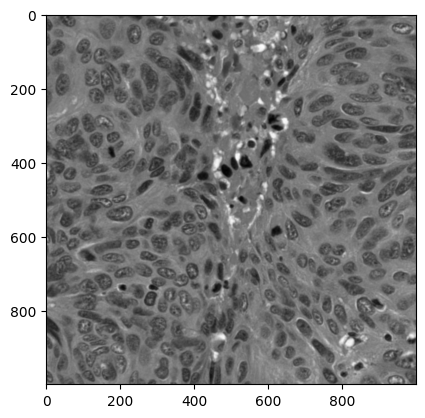

In [121]:
# blur image
blur = cv.GaussianBlur(gray, (5, 5), 0)
plt.imshow(blur, cmap='gray')
cv.imshow('blurred image', blur)
cv.waitKey(0)
cv.destroyAllWindows()

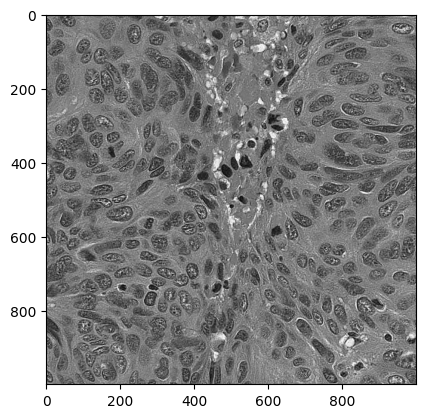

In [122]:
# sharpen image
kernel = np.array([[-1, -1, -1],
                   [-1, 9, -1],
                   [-1, -1, -1]])
sharpened = cv.filter2D(gray, -1, kernel)
plt.imshow(sharpened, cmap='gray')
cv.imshow('sharpened image', sharpened)
cv.waitKey(0)
cv.destroyAllWindows()

number of contours: 192
[12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0] [256.5, 280.0, 365.0, 1105.0, 1183.5, 1749.0, 1823.0, 3449.0, 6357.0, 863487.0]


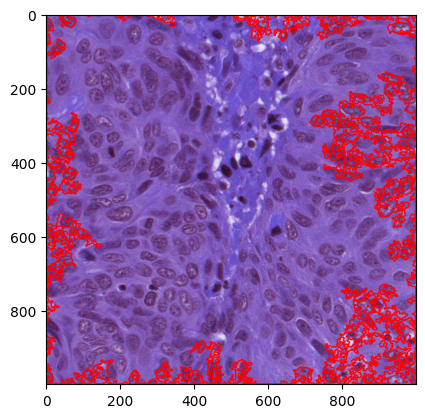

In [123]:
# ATTEMPT 2

# subtract blurred image from original
sub = cv.subtract(gray, sharpened)
# dilate image
kernel = np.ones((3, 3), np.uint8)
dil = cv.dilate(sub, kernel, iterations=1)
# threshold dilated image
ret, thresh = cv.threshold(dil, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
# erode image
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
erode = cv.erode(thresh, kernel, iterations=2)
# opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
thresh = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=2)
# contours
contours, _ = cv.findContours(thresh, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 10]
print(f'number of contours: {len(contours)}')
sizes = list(sorted([cv.contourArea(c) for c in contours]))
print(sizes[:10], sizes[-10:])
img_copy = img.copy()
img_copy = cv.drawContours(img_copy, contours, -1, (255, 0, 0), 2)
plt.imshow(img_copy, cmap='gray')
cv.imshow('contours image', img_copy)
# cv.imshow('thresh image', thresh)
# cv.imshow('erode image', erode)
cv.waitKey(0)
cv.destroyAllWindows()

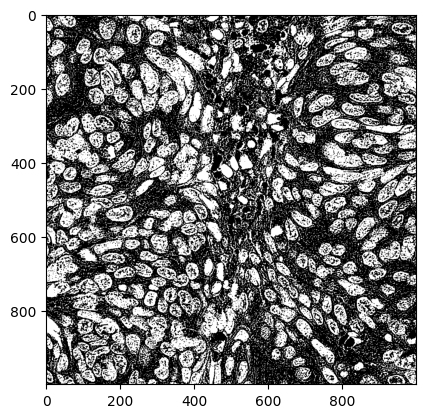

In [145]:
# threshold sharpened image
ret, thresh = cv.threshold(sharpened, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
plt.imshow(thresh, cmap='gray')
cv.imshow('thresholded image', thresh)
cv.waitKey(0)
cv.destroyAllWindows()

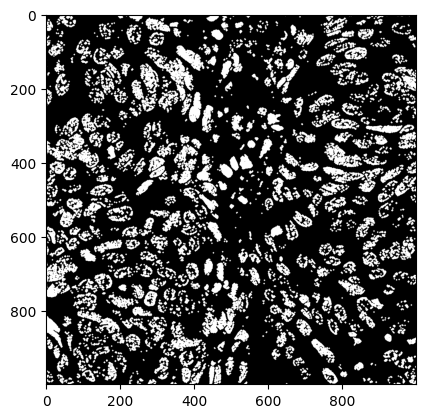

In [153]:
# morphological opening
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel, iterations=2)
plt.imshow(opening, cmap='gray')
cv.imshow('opening image', opening)
cv.waitKey(0)
cv.destroyAllWindows()

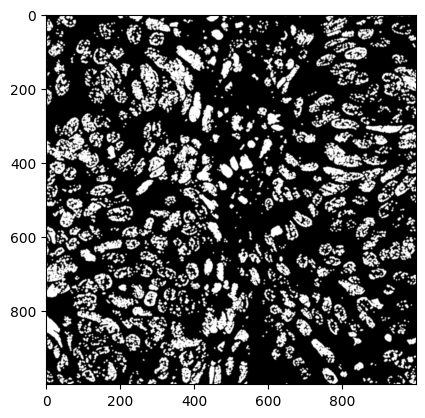

In [154]:
# blur
blurred = cv.blur(opening, (3, 3))
plt.imshow(blurred, cmap='gray')
cv.imshow('blurred image', blurred)
cv.waitKey(0)
cv.destroyAllWindows()

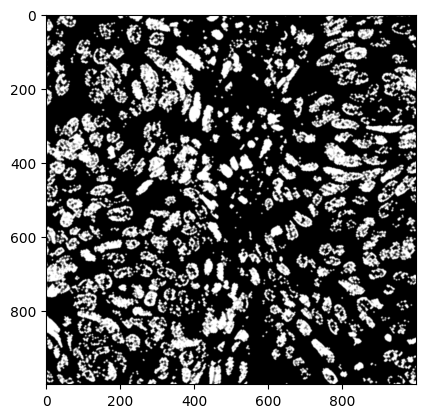

In [159]:
# morphological closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(blurred, cv.MORPH_CLOSE, kernel, iterations=2)
plt.imshow(closing, cmap='gray')
cv.imshow('closing image', closing)
cv.waitKey(0)
cv.destroyAllWindows()

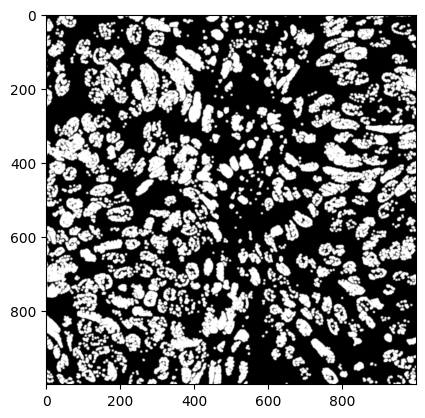

In [156]:
# dilate image
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(closing, kernel, iterations=1)
plt.imshow(dilated, cmap='gray')
cv.imshow('dilated image', dilated)
cv.waitKey(0)
cv.destroyAllWindows()

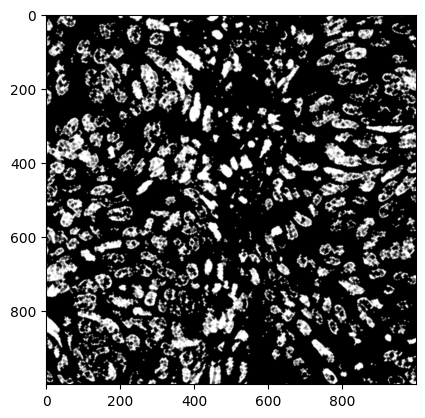

In [160]:
# erode image
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
eroded = cv.erode(closing, kernel, iterations=1)
plt.imshow(eroded, cmap='gray')
cv.imshow('eroded image', eroded)
cv.waitKey(0)
cv.destroyAllWindows()

number of contours: 328


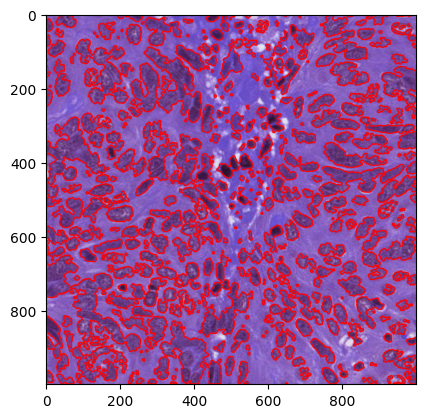

In [161]:
# contours
contours, _ = cv.findContours(closing, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 10]
print(f'number of contours: {len(contours)}')
img_copy2 = img.copy()
img_copy2 = cv.drawContours(img_copy2, contours, -1, (255, 0, 0), 2)
plt.imshow(img_copy2, cmap='gray')
cv.imshow('contours image 1', img_copy)
cv.imshow('contours image 2', img_copy2)
cv.waitKey(0)
cv.destroyAllWindows()

# NOTE: method with image 1 seems a little better

In [57]:
# draw contours
count_img = cv.drawContours(img.copy(), contours, -1, (255, 0, 0), 2)
cv.imshow('contours', count_img)
cv.waitKey(0)
cv.destroyAllWindows()

In [33]:
ContourSizeTracker(eroded, window='contours', min_area=10, max_area=50, mode=cv.RETR_EXTERNAL)

number of white regions: 1233


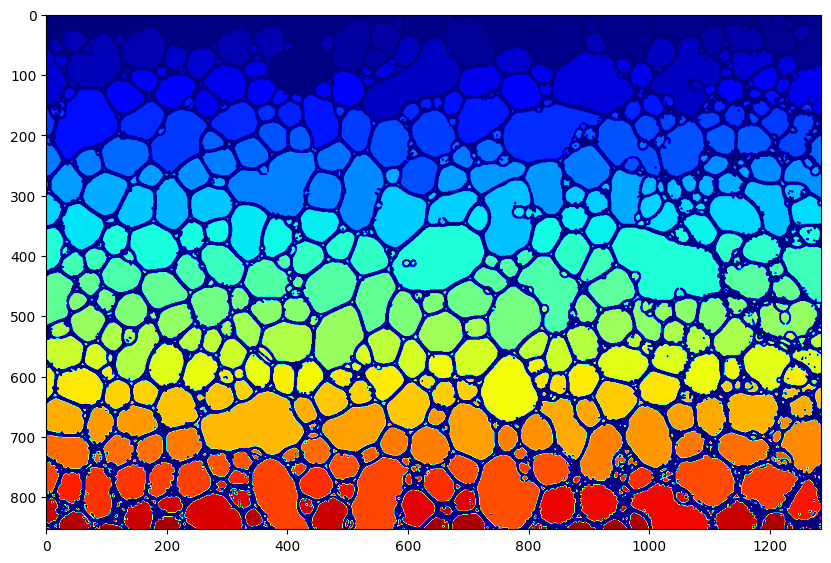

In [96]:
# count number of white regions
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(eroded)
print(f'number of white regions: {num_labels - 1}')

# show white regions
plt.figure(figsize=(10, 10))
plt.imshow(labels, cmap='jet')
plt.show()

In [9]:
AdaptiveThresholdTracker(gray, window='adaptive threshold')

In [11]:
gray = cv.cvtColor(org_img.copy(), cv.COLOR_BGR2GRAY)
blurred = cv.medianBlur(gray, 5)
cv.imshow('original', org_img)
AdaptiveThresholdTracker(blurred, window='blur adaptive threshold', ksize=5)

In [12]:
img = org_img.copy()

# Convert to grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Apply Gaussian blur
blur = cv.GaussianBlur(gray, (3, 3), 0)

# Apply adaptive thresholding
thresh = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 5, 2)

# Apply opening to remove small dots and thin edges
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
opening = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel)

# Display the result
cv.imshow('Opening', opening)
cv.waitKey(0)
cv.destroyAllWindows()

In [47]:
target_img = img
GaussianTracker(target_img, window='gaussian blur')
# MedianTracker(target_img, window='median blur')
# BilateralTracker(target_img, window='bilateral blur')

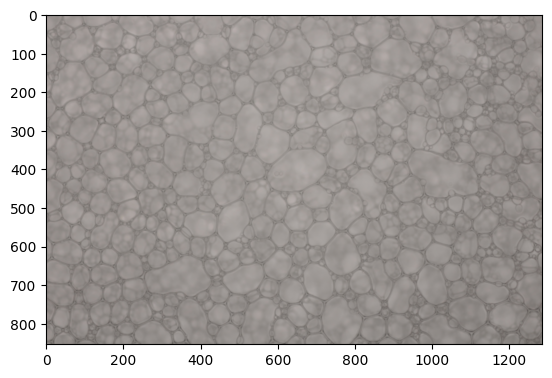

In [127]:
# gaussian blur
gaussian = cv.GaussianBlur(img, (5, 5), 0)
plt.imshow(cv.cvtColor(gaussian, cv.COLOR_BGR2RGB))
cv.imshow('gaussian', gaussian)
cv.waitKey(0)
cv.destroyAllWindows()

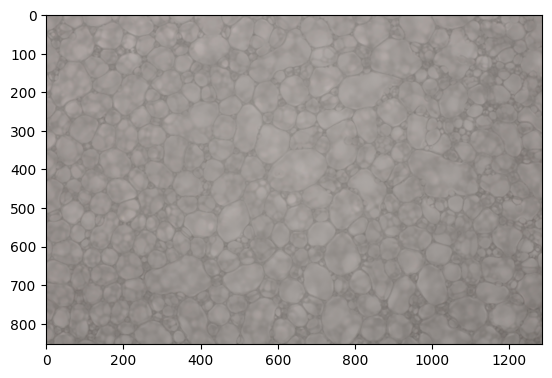

In [134]:
# median blur
median = cv.medianBlur(img, 5)
plt.imshow(cv.cvtColor(median, cv.COLOR_BGR2RGB))
cv.imshow('median', median)
cv.waitKey(0)
cv.destroyAllWindows()

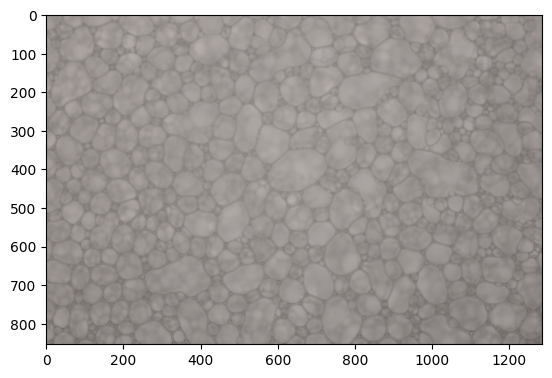

In [135]:
# bilateral blur
bilateral = cv.bilateralFilter(img, 9, 75, 75)
plt.imshow(cv.cvtColor(bilateral, cv.COLOR_BGR2RGB))
cv.imshow('bilateral', bilateral)
cv.waitKey(0)
cv.destroyAllWindows()

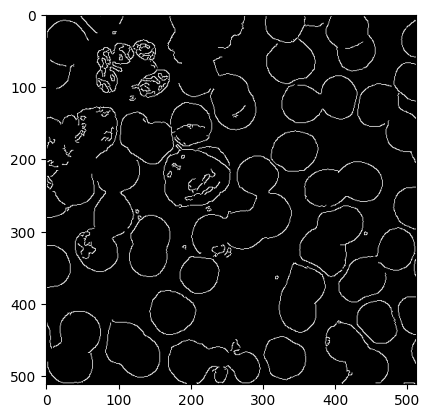

In [53]:
# canny
edges = cv.Canny(img, 100, 200)
plt.imshow(cv.cvtColor(edges, cv.COLOR_BGR2RGB))
cv.imshow('edges', edges)
cv.waitKey(0)
cv.destroyAllWindows()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


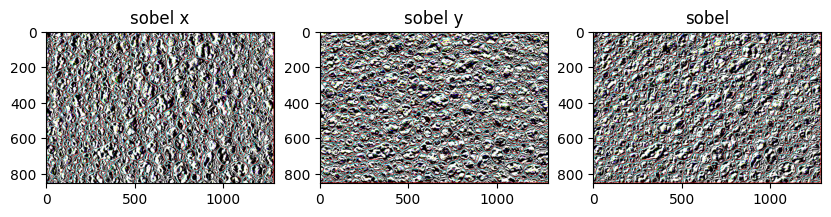

In [104]:
# sobel
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=5)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=5)
# merge images 2 sobel images
sobel = cv.addWeighted(sobelx, 0.5, sobely, 0.5, 0)
# show images next to each other
plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.title('sobel x')
plt.imshow(sobelx)
plt.subplot(1, 3, 2)
plt.title('sobel y')
plt.imshow(sobely)
plt.subplot(1, 3, 3)
plt.title('sobel')
plt.imshow(sobel)
plt.show()
# cv.imshow('sobelx', sobelx)
# cv.imshow('sobely', sobely)
# cv.imshow('sobel', sobel)
# cv.waitKey(0)
# cv.destroyAllWindows()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


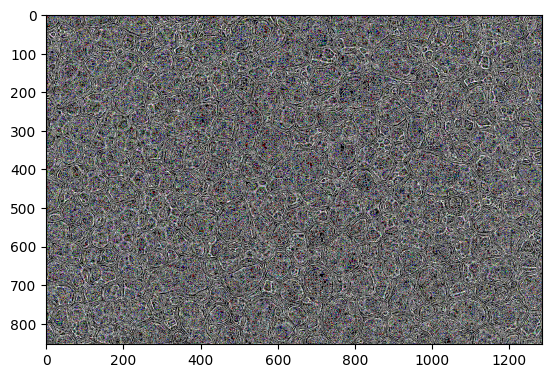

In [106]:
# laplacian
laplacian = cv.Laplacian(org_img.copy(), cv.CV_64F)
plt.imshow(laplacian)